#### FFW SG2 - Motion Executor, **one joint at a time**

A variant of `sim_motion_executor_test.ipynb`. Everything is the same -- same scene, same wrist
gizmos, same command window, same output stage -- **except how a segment is interpolated**.

| | `sim_motion_executor_test.ipynb` | this notebook |
|---|---|---|
| planner | `plan_min_jerk` | `plan_sequential` (defined below) |
| joints during a segment | all move together | exactly one moves at a time |
| duration of a segment | `max` over joints | `sum` over joints |
| joint-space path | one straight line | an axis-aligned staircase |

**What "together" means in the original.** `plan_min_jerk` builds

    qpos = q_start + s(tau)[:, None] * (q_goal - q_start)[None, :]

`s(tau)` has no joint axis: every joint shares one progress scalar, so they start together, finish
together, and their speeds stay in the fixed ratio `v_1 : v_2 = D_1 : D_2` throughout. The joint
that needs the longest `T` sets the pace and the rest are slowed to match.

**What this notebook does instead.** One joint is driven to its goal with its own min-jerk
profile while every other joint holds; when it arrives, the next one starts. Each leg still has
`s'(0)=s'(1)=0` and `s''(0)=s''(1)=0`, so the handover between legs is not a jolt -- the robot
comes to a full stop between joints.

**What you give up.** The total duration becomes the sum rather than the max, so a segment that
took 2.5 s takes ~11 s. And the joint-space path is no longer a straight line: it is a staircase
along the coordinate axes, which sweeps a *larger* region of the workspace than the straight line
did. The collision sweep in the offline cell is the thing to read -- a sequential path can hit the
table on a segment the synchronized path cleared, because it drives one joint all the way out
before starting to bring the next one back.

**What you gain.** Every moment of the motion has exactly one joint moving, which makes it
trivially attributable: the per-leg table below names the joint, its travel, and its duration, and
the collision log can be traced to a single joint rather than to a combination.

`SEQUENTIAL_ORDER_MODE` at the top of the planner cell picks the order:
`"largest"` (largest travel first, the default), `"command"` (the executor's array order:
lift, head, left arm, right arm, grippers) or `"distal"` (that order reversed).

In [1]:
%run ../package/init_project.py

import numpy as np

from ri_motion_v5_package.init_scripts.init_ipython_setup import *
from ri_motion_v5_package.init_scripts.init_qt import *
from ri_motion_v5_package.mujoco_sim import *
from ri_motion_v5_package.kinematics import *
from ri_motion_v5_package.utility import *
from ri_motion_v5_package.qt import *
from utils import *
from package.joint_control import *        # not `from joint_control import *`: IPython's %run puts
from package.joint_marker_control import * # PACKAGE_DIR on sys.path only during the run
from package.joint_marker_real import *    # speed limits + apply_sg2_joint_rate_limit
from package.motion_executor import *      # min-jerk planner, SG2MotionExecutor, bring-up waypoints

app = get_qt_app()


[ffw_sg2_vr_teleoperation] initialized.
 - PROJECT_DIR: /Users/yongjoo/dev/VAI_AIWORKER/ri_motion_v5_VR/project/ffw_sg2_vr_teleoperation
Basic packages initialized.
 import numpy as np
 import matplotlib.pyplot as plt
 import scipy as sp
 from PIL import Image
[ipython] settings (retina, inline, qt) initialized.
[numpy] settings initialized.
[matplotlib] settings initialized.
[qt] package initialized.


In [2]:
xml_path = merge_mjcfs(
    included_mjcf_files = [
        str(FLOOR_XML_PATH),
        str(SG2_XML_PATH),
        str(SG2_PROJECT_XML_DIR / "table.xml"),  # same scene as sim_joint_controller_sg2_teleop_with_table
    ],
    output_xml_path = str(SG2_SCENE_XML_PATH),)
env = MuJoCoParser(rel_xml_path=xml_path,verbose=False)
env.reset()
env.set_p("base_link","body",(0.0,0.0,0.01))

# Bend the elbows into a natural pose so both wrists start away from IK singularities.
env.forward(
    q           = [np.deg2rad(-90.0),np.deg2rad(-90.0)],
    joint_names = ["arm_l_joint4","arm_r_joint4"],)

# Same joint set the real robot takes over ZMQ: lift + head + both arms + both gripper drivers.
# The executor works in this order throughout; note it differs from the arm-only IK joint order.
command_joint_names = filter_existing_joint_names(
    env,
    list(SG2_REAL_COMMAND_JOINT_NAMES)
    + [SG2_GRIPPER_DRIVER_JOINT_NAMES[hand_type] for hand_type in SG2_HAND_TYPES],)
print(f"command joints ({len(command_joint_names)}): {command_joint_names}")

[merge_mjcfs] Merging [3] MJCF files:
  - [0] [/Users/yongjoo/dev/VAI_AIWORKER/ri_motion_v5_VR/project/ffw_sg2_vr_teleoperation/xml/floor_simple_white.xml]
  - [1] [/Users/yongjoo/dev/VAI_AIWORKER/ri_motion_v5_VR/project/ffw_sg2_vr_teleoperation/xml/ffw_sg2.xml]
  - [2] [/Users/yongjoo/dev/VAI_AIWORKER/ri_motion_v5_VR/project/ffw_sg2_vr_teleoperation/xml/table.xml]
[merge_mjcfs] Saved merged XML to:[/Users/yongjoo/dev/VAI_AIWORKER/ri_motion_v5_VR/project/ffw_sg2_vr_teleoperation/xml/scene_ffw_sg2_metaquest3.xml]
MuJoCo model loaded from [/Users/yongjoo/dev/VAI_AIWORKER/ri_motion_v5_VR/project/ffw_sg2_vr_teleoperation/xml/scene_ffw_sg2_metaquest3.xml].
command joints (19): ['lift_joint', 'head_joint1', 'head_joint2', 'arm_l_joint1', 'arm_l_joint2', 'arm_l_joint3', 'arm_l_joint4', 'arm_l_joint5', 'arm_l_joint6', 'arm_l_joint7', 'arm_r_joint1', 'arm_r_joint2', 'arm_r_joint3', 'arm_r_joint4', 'arm_r_joint5', 'arm_r_joint6', 'arm_r_joint7', 'gripper_l_joint1', 'gripper_r_joint1']


In [3]:
# One small (non-collision-aware) DLS IK solver per arm, each restricted to that arm's joints.
ik_solvers,arm_joint_names = create_sg2_arm_ik_solvers(
    env                = env,
    mujoco_parser_cls  = MuJoCoParser,
    body_ik_solver_cls = BodyPositionIKSolverRevPriBase,)
for hand_type in SG2_HAND_TYPES:
    print(f"{hand_type} arm IK joints ({len(arm_joint_names[hand_type])}): {arm_joint_names[hand_type]}")

# Collision is only monitored here: signed distances are reported, never corrected.
# The candidate pairs are "one geom on the robot vs any other collision geom", so with
# table.xml merged into the scene the robot-vs-table pairs come along for free -- the
# same call now covers self-collision AND the table.
collision_geom_pairs,collision_candidate_info = create_sg2_collision_candidate_geom_pairs(
    env               = env,
    init_exclude_dist = 0.05,)
print_sg2_collision_candidate_summary(collision_candidate_info)

# Split the candidates into self-collision and robot-vs-table, so it is visible that the
# table actually entered the set (an empty table row means the merge or the pose filter
# dropped it, and the run would then report "safe" while an arm goes through the top).
table_geom_idxs = set(env.get_geom_idxs_from_root_body_name("table"))
env_pair_idxs   = [i for i,(g1,g2) in enumerate(collision_geom_pairs)
                   if int(g1) in table_geom_idxs or int(g2) in table_geom_idxs]
print("  self-collision pairs:[%d]" % (len(collision_geom_pairs)-len(env_pair_idxs)))
print("  robot-table pairs   :[%d]" % len(env_pair_idxs))
print("  table geoms         :", [env.geom_names[g] for g in sorted(table_geom_idxs)])

# The compiled backend is optional in this notebook; without it the pure-Python path is used.
native_backend = build_sg2_collision_aware_ik_backend(
    clean    = False,
    verbose  = False,
    required = False,)
print(f"signed distance backend: {'native' if native_backend is not None else 'python'}")

MuJoCo model loaded from [/Users/yongjoo/dev/VAI_AIWORKER/ri_motion_v5_VR/project/ffw_sg2_vr_teleoperation/xml/scene_ffw_sg2_metaquest3.xml].
MuJoCo model loaded from [/Users/yongjoo/dev/VAI_AIWORKER/ri_motion_v5_VR/project/ffw_sg2_vr_teleoperation/xml/scene_ffw_sg2_metaquest3.xml].
left arm IK joints (7): ['arm_l_joint1', 'arm_l_joint2', 'arm_l_joint3', 'arm_l_joint4', 'arm_l_joint5', 'arm_l_joint6', 'arm_l_joint7']
right arm IK joints (7): ['arm_r_joint1', 'arm_r_joint2', 'arm_r_joint3', 'arm_r_joint4', 'arm_r_joint5', 'arm_r_joint6', 'arm_r_joint7']
Collision candidates
--------------------
robot collision geom:[34]
collision geom:[40]
candidate geom pairs:[643]
excluded initial geom pairs:[57]
  self-collision pairs:[493]
  robot-table pairs   :[150]
  table geoms         : ['table_top', 'table_leg1', 'table_leg2', 'table_leg3', 'table_leg4']
signed distance backend: native


**The sequential planner**

`plan_sequential` has the same contract as `plan_min_jerk` -- in, two joint poses and the speed and
acceleration ceilings; out, a `qpos` array the loop consumes one row per tick -- and two extra keys,
`joint_idx` (which joint is moving at each sample) and `legs`.

The difference is one line of shape. `plan_min_jerk` writes

    qpos = q_start + s(tau)[:, None] * (q_goal - q_start)[None, :]

where `s` has no joint axis, so all joints share one progress scalar. `plan_sequential` instead
loops over the joints that need to move and, for each, builds a block where that column follows its
own `s` and every other column holds its current value. The blocks are concatenated, so the
durations add rather than take the max.

Two details worth knowing:

- **each leg gets its own duration** from `estimate_duration` on its own displacement alone. A joint
  that has to travel 80 deg gets 2.5 s; one that travels 4 deg gets the 0.5 s `min_duration` floor.
- **each leg starts one sample in** (`tau` runs from `dt/T`, not from 0). `tau = 0` would repeat the
  sample the previous leg ended on, which shows up in the log as a tick where nothing moved.

`SG2SequentialMotionExecutor` subclasses `SG2MotionExecutor` and overrides `_plan_next_segment` and
nothing else. The output stage -- `env.forward` -> `apply_sg2_joint_rate_limit` -> `np.clip` ->
`env.forward` -- and every method the loop calls are inherited unchanged, so any difference in the
analysis at the bottom can only have come from the planner.

In [4]:
# The sequential planner and the executor that uses it.
# Kept in the notebook rather than in package/motion_executor.py: this is a
# comparison against that module's plan_min_jerk, so the two must be able to
# differ without one editing the other.

SEQUENTIAL_ORDER_MODE = "largest"    # "largest" | "command" | "distal"

# ---------------------------------------------------------------------------
# Sequential planner -- one joint at a time
# ---------------------------------------------------------------------------
def sequential_joint_order(joint_names, mode="command"):
    """The order the joints are driven in. `mode`:
        "command"  -- the executor's own array order (lift, head, left arm, right arm, grippers)
        "distal"   -- reversed: wrist first, shoulder last
        "largest"  -- resolved per segment against the actual travel (handled in the planner)
    """
    idxs = list(range(len(joint_names)))
    if mode == "command":
        return idxs
    if mode == "distal":
        return idxs[::-1]
    if mode == "largest":
        return None                      # planner sorts by |dq| itself
    raise ValueError(f"unknown order mode: {mode}")


def plan_sequential(q_start, q_goal, v_max, a_max, hz=100.0, min_duration=0.5,
                    order=None, joint_tol=1e-6):
    """Min-jerk trajectory that moves ONE joint at a time, back to back.

    Same return contract as `plan_min_jerk` plus two extra keys:
        "joint_idx" : (L,) int  -- which joint is moving at each sample (-1 = none)
        "legs"      : list of (joint_idx, t_start, t_end, travel)

    Each joint gets its own duration from `estimate_duration` on its own
    displacement, so the total is the SUM of the legs rather than the max. The
    profile within a leg is the same quintic, so every leg still starts and ends
    at zero velocity and zero acceleration -- there is no jolt at a handover.
    """
    q_start = np.asarray(q_start, dtype=np.float64).ravel()
    q_goal  = np.asarray(q_goal,  dtype=np.float64).ravel()
    if q_start.shape != q_goal.shape:
        raise ValueError(f"q_start/q_goal shape mismatch: {q_start.shape} vs {q_goal.shape}")
    if hz <= 0.0:
        raise ValueError("hz must be positive.")
    n     = q_start.size
    v_max = np.broadcast_to(np.asarray(v_max, dtype=np.float64).ravel(), (n,))
    a_max = np.broadcast_to(np.asarray(a_max, dtype=np.float64).ravel(), (n,))
    dt    = 1.0 / float(hz)

    delta = q_goal - q_start
    if order is None:
        movers = sorted(np.where(np.abs(delta) > joint_tol)[0],
                        key=lambda j: -abs(delta[j]))          # largest travel first
    else:
        movers = [j for j in order if abs(delta[j]) > joint_tol]

    # Nothing to do: hold for min_duration so the caller still gets a valid segment.
    if len(movers) == 0:
        n_step = max(int(np.ceil(float(min_duration) / dt)), 1)
        times  = np.arange(n_step + 1, dtype=np.float64) * dt
        return {"times": times,
                "qpos" : np.tile(q_start, (n_step + 1, 1)),
                "qvel" : np.zeros((n_step + 1, n)),
                "qacc" : np.zeros((n_step + 1, n)),
                "duration": float(times[-1]), "hz": float(hz),
                "joint_idx": np.full(n_step + 1, -1, dtype=int), "legs": []}

    q_cur   = q_start.copy()
    t_now   = 0.0
    times_l = [np.zeros(1)]
    qpos_l  = [q_start[None, :].copy()]
    qvel_l  = [np.zeros((1, n))]
    qacc_l  = [np.zeros((1, n))]
    jidx_l  = [np.array([movers[0]])]
    legs    = []

    for j in movers:
        d = q_goal[j] - q_cur[j]
        # Duration from this one joint's displacement -- estimate_duration takes
        # arrays, so pass the single-element slice rather than the whole vector.
        T = estimate_duration(np.array([q_cur[j]]), np.array([q_goal[j]]),
                              np.array([v_max[j]]), np.array([a_max[j]]),
                              min_duration=min_duration)
        n_step = max(int(np.ceil(T / dt)), 1)
        T      = n_step * dt
        # tau starts at one step in: tau=0 would repeat the sample the previous
        # leg already ended on, which shows up as a stalled tick in the log.
        tau        = (np.arange(1, n_step + 1, dtype=np.float64) * dt) / T
        s, ds, dds = min_jerk_scalar(tau)

        block_q = np.tile(q_cur, (n_step, 1))
        block_v = np.zeros((n_step, n))
        block_a = np.zeros((n_step, n))
        block_q[:, j] = q_cur[j] + s * d
        block_v[:, j] = ds * d / T
        block_a[:, j] = dds * d / (T * T)

        times_l.append(t_now + np.arange(1, n_step + 1, dtype=np.float64) * dt)
        qpos_l.append(block_q); qvel_l.append(block_v); qacc_l.append(block_a)
        jidx_l.append(np.full(n_step, j, dtype=int))
        legs.append((int(j), float(t_now), float(t_now + T), float(abs(d))))

        q_cur = block_q[-1].copy()
        t_now += T

    times = np.concatenate(times_l)
    return {"times": times,
            "qpos" : np.concatenate(qpos_l,  axis=0),
            "qvel" : np.concatenate(qvel_l,  axis=0),
            "qacc" : np.concatenate(qacc_l,  axis=0),
            "duration": float(times[-1]), "hz": float(hz),
            "joint_idx": np.concatenate(jidx_l), "legs": legs}


class SG2SequentialMotionExecutor(SG2MotionExecutor):
    """SG2MotionExecutor with plan_sequential in place of plan_min_jerk.

    Only `_plan_next_segment` changes. The output stage -- env.forward ->
    apply_sg2_joint_rate_limit -> np.clip -> env.forward -- and everything the
    loop touches are inherited unchanged, so a difference in the analysis below
    can only have come from the planner.
    """

    def __init__(self, *args, order_mode=SEQUENTIAL_ORDER_MODE, **kwargs):
        self.order_mode = order_mode
        super().__init__(*args, **kwargs)      # calls reset(), so set attrs first

    def _plan_next_segment(self):
        if len(self.goal_queue) == 0:
            self.traj = None
            self.segment_label = ""
            return False
        self.segment_label, q_goal = self.goal_queue.pop(0)
        self.segment_idx += 1
        self.traj = plan_sequential(
            q_start      = self.q_use,
            q_goal       = q_goal,
            v_max        = self.speed_limits,
            a_max        = self.acc_limits,
            hz           = self.hz,
            min_duration = self.min_duration,
            order        = sequential_joint_order(self.joint_names, self.order_mode),)
        self.step_idx = 0
        return True

    def active_joint_name(self):
        """The joint this tick will move. Read it BEFORE tick(), which advances
        step_idx -- afterwards it names the next leg, not the one just executed."""
        if self.traj is None:
            return ""
        idx = min(self.step_idx, len(self.traj["joint_idx"]) - 1)
        j   = int(self.traj["joint_idx"][idx])
        return self.joint_names[j] if j >= 0 else "hold"

    def leg_label(self):
        """`segment/joint` -- the label the log uses. In this notebook the
        per-joint leg IS the unit of motion, so it is what the plots name."""
        joint = self.active_joint_name()
        return f"{self.segment_label}/{joint}" if joint else self.segment_label

    def status_text(self):
        base = super().status_text()
        joint = self.active_joint_name()
        return base if not joint else f"{base}\n  moving: {joint}"


print(f"order mode: {SEQUENTIAL_ORDER_MODE}")


# ---------------------------------------------------------------------------
# Shared helpers: where the wrists go, and how straight that path is
# ---------------------------------------------------------------------------
# The joint plots cannot answer "did the hand go straight up?", because the step
# is *specified* in Cartesian space and *executed* in joint space. Replaying the
# planned qpos through FK is what closes that gap -- env.forward is kinematics
# only, so it costs nothing and leaves no trace.
def wrist_path_from_qpos(env, joint_names, qpos, n_max=240, hand_types=SG2_HAND_TYPES):
    """FK replay: (idxs, {hand: (k,3) wrist positions}). Restores the pose it found."""
    qpos   = np.asarray(qpos, dtype=np.float64)
    stride = max(1, int(np.ceil(len(qpos) / n_max)))
    idxs   = np.arange(0, len(qpos), stride)
    if idxs[-1] != len(qpos) - 1:
        idxs = np.append(idxs, len(qpos) - 1)      # never drop the endpoint
    q_before = env.get_qpos(joint_names=joint_names).copy()
    out = {hand_type: np.zeros((len(idxs), 3)) for hand_type in hand_types}
    try:
        for row, idx in enumerate(idxs):
            env.forward(q=qpos[idx], joint_names=joint_names)
            for hand_type in hand_types:
                out[hand_type][row] = t2p(get_sg2_wrist_control_T(env, hand_type))
    finally:
        env.forward(q=q_before, joint_names=joint_names)
    return idxs, out


def path_straightness(P):
    """Largest perpendicular distance [m] from the chord joining the endpoints.

    0 means the wrist travelled the straight line between where it started and
    where it finished. This is the one number that separates a Cartesian route
    from a joint-space one: both reach the same endpoint, only the bulge differs.
    """
    P = np.asarray(P, dtype=np.float64)
    d = P[-1] - P[0]
    L = float(np.linalg.norm(d))
    if L < 1e-9:
        return 0.0, L
    u   = d / L
    rel = P - P[0]
    perp = rel - np.outer(rel @ u, u)
    return float(np.max(np.linalg.norm(perp, axis=1))), L

order mode: largest


**Offline check -- the waypoints and both routes, before anything moves**

Same three checks as `sim_motion_executor_test.ipynb` (joint limits, per-segment plan, collision
sweep), with the **synchronized plan computed alongside the sequential one** at every step so the
cost of the change is visible rather than asserted.

- **duration.** The `T seq` / `T sync` columns and the `slower` ratio. The sum-vs-max difference is
  the whole story: expect 3-5x.
- **the legs.** One indented line per joint under each segment, in the order they will be driven,
  with the duration and travel of each. Nothing like this exists for the synchronized planner --
  there, every joint is smeared across the whole segment.
- **the wrist route.** Both plans end at the same joint pose and therefore at the same wrist pose;
  only the route between differs. `bulge` is the largest perpendicular distance from the straight
  line joining the endpoints. A staircase does not cut the corner, so expect the sequential bulge to
  be the larger one -- often by a lot.
- **collisions.** Run for **both** routes on every segment. This is the row that matters most in this
  notebook: a larger bulge sweeps a larger region, so a segment that was clear when all the joints
  moved together can put a wrist through the table when one joint is driven all the way out before
  the next starts to come back. The `sync` rows are there for comparison only; only the `seq` rows
  feed the verdict.

`v/v_max` and `a/a_max` at or below 1.0 means pass. Ratios come from **differentiating the `qpos`
array** rather than from the analytic `traj["qvel"]` -- the loop consumes `qpos` and nothing else.

This cell plans the **joint-space legs only** (`SG2_MOTION_SEQUENCES`). `shut_down`'s two pre-steps
-- open the grippers, lift the wrists -- are built from the live pose at command time by
`build_sg2_shut_down_goals`, so they cannot be checked ahead of time here.

In [5]:
# Offline check -- plan the sequence BOTH ways and put the two side by side

SEQUENCE_NAME = "bring_up"     # "bring_up" or "shut_down"

joint_speed_limits = get_sg2_joint_speed_limits(env=env, joint_names=command_joint_names)
joint_acc_limits   = get_sg2_joint_acc_limits(env=env, joint_names=command_joint_names)
plan_hz            = 100.0

print(f"revolute  v_max {SG2_MAX_REV_JOINT_SPEED:.4f} rad/s ({np.rad2deg(SG2_MAX_REV_JOINT_SPEED):.1f} deg/s)"
      f" | a_max {SG2_MAX_REV_JOINT_ACC:.4f} rad/s^2")
print(f"prismatic v_max {SG2_MAX_PRI_JOINT_SPEED:.4f} m/s              | a_max {SG2_MAX_PRI_JOINT_ACC:.4f} m/s^2")
print(f"(acceleration is provisional: v_max / {SG2_JOINT_ACC_RAMP_SEC:.2f}s -- verify against the motor specs)\n")

# ---------------------------------------------------------------------------
# 1) Expand the waypoints by joint name and check them against the joint limits
# ---------------------------------------------------------------------------
step_names = SG2_MOTION_SEQUENCES[SEQUENCE_NAME]
# bring_up and shut_down read from different waypoint tables now, so pick by name.
waypoint_table = SG2_SHUTDOWN_WAYPOINTS if SEQUENCE_NAME == "shut_down" else SG2_BRINGUP_WAYPOINTS
waypoints  = [(name, expand_sg2_qpos(command_joint_names, waypoint_table[name]))
              for name in step_names]

all_ok = True
for name, q in waypoints:
    limit_info = check_sg2_joint_limits(env, command_joint_names, q)
    all_ok = all_ok and limit_info["ok"]
    nonzero = [f"{n}={v:+.4f}" for n, v in zip(command_joint_names, q) if abs(v) > 1e-9]
    print(f"[{name:>5s}] joint limits {'OK' if limit_info['ok'] else 'VIOLATED'} | {', '.join(nonzero)}")
    if not limit_info["ok"]:
        print(format_sg2_joint_limit_violations(limit_info))

# ---------------------------------------------------------------------------
# 2) Plan each segment sequentially, with the synchronized plan alongside
# ---------------------------------------------------------------------------
# Both planners are seeded from the same pose at every segment, so the only
# difference between the two columns is the interpolation.
q_seg    = env.get_qpos(joint_names=command_joint_names)
segments = []
print(f"\nplanning {SEQUENCE_NAME}: current pose -> {' -> '.join(step_names)}")
print(f"{'segment':>10s} {'T seq':>7s} {'T sync':>7s} {'slower':>7s} {'legs':>5s} "
      f"{'v/v_max':>8s} {'a/a_max':>8s}  flag")
print("-" * 74)

total_seq = total_sync = 0.0
for name, q_goal in waypoints:
    traj = plan_sequential(
        q_start = q_seg, q_goal = q_goal,
        v_max = joint_speed_limits, a_max = joint_acc_limits,
        hz = plan_hz, min_duration = 0.5,
        order = sequential_joint_order(command_joint_names, SEQUENTIAL_ORDER_MODE),)
    traj_sync = plan_min_jerk(
        q_start = q_seg, q_goal = q_goal,
        v_max = joint_speed_limits, a_max = joint_acc_limits,
        hz = plan_hz, min_duration = 0.5,)

    # Differentiate the qpos array itself -- that array is all the loop consumes.
    dt_plan = 1.0 / plan_hz
    v_num   = np.diff(traj["qpos"], axis=0) / dt_plan
    a_num   = np.diff(v_num,        axis=0) / dt_plan
    v_ratio = np.abs(v_num) / joint_speed_limits[None, :]
    a_ratio = np.abs(a_num) / joint_acc_limits[None, :]
    flag = ("V!" if v_ratio.max() > 1.0 + 1e-6 else "  ") + ("A!" if a_ratio.max() > 1.0 + 1e-6 else "  ")
    all_ok = all_ok and v_ratio.max() <= 1.0 + 1e-6 and a_ratio.max() <= 1.0 + 1e-6

    print(f"{name:>10s} {traj['duration']:7.2f} {traj_sync['duration']:7.2f} "
          f"{traj['duration'] / max(traj_sync['duration'], 1e-9):6.2f}x "
          f"{len(traj['legs']):5d} {v_ratio.max():8.4f} {a_ratio.max():8.4f}  {flag}")
    # Only one joint is moving at any moment, so the legs ARE the motion: this is
    # the breakdown the synchronized planner cannot give, where every joint is
    # smeared across the whole segment.
    for j, t0, t1, travel in traj["legs"]:
        unit = (f"{1e3 * travel:8.1f} mm" if command_joint_names[j] in set(env.pri_joint_names)
                else f"{np.rad2deg(travel):8.1f} deg")
        print(f"{'':>12s}{t0:6.2f}..{t1:5.2f}s  {command_joint_names[j]:<18s}{unit}")

    segments.append({"name": name, "traj": traj, "traj_sync": traj_sync})
    total_seq  += traj["duration"]
    total_sync += traj_sync["duration"]
    q_seg = q_goal

print("-" * 74)
print(f"{'total':>10s} {total_seq:7.2f} {total_sync:7.2f} "
      f"{total_seq / max(total_sync, 1e-9):6.2f}x")

# ---------------------------------------------------------------------------
# 3) What the two routes do to the wrist
# ---------------------------------------------------------------------------
# Both plans end at the same joint pose, so both end at the same wrist pose. What
# differs is the route in between: driving one joint to its goal before starting
# the next swings the wrist out along the coordinate axes instead of cutting the
# corner, so the bulge away from the straight line is the number to compare.
print(f"\nwrist route (max bulge away from the straight line between the endpoints)")
print(f"{'segment':>10s} {'hand':>6s} {'chord [m]':>10s} {'seq [mm]':>10s} {'sync [mm]':>11s} {'ratio':>7s}")
print("-" * 62)
for segment in segments:
    for label, key in (("seq", "traj"), ("sync", "traj_sync")):
        _, segment[f"path_{label}"] = wrist_path_from_qpos(
            env, command_joint_names, segment[key]["qpos"], n_max=200)
    for hand_type in SG2_HAND_TYPES:
        bulge_seq,  chord = path_straightness(segment["path_seq"][hand_type])
        bulge_sync, _     = path_straightness(segment["path_sync"][hand_type])
        if chord < 1e-4:
            continue
        print(f"{segment['name']:>10s} {hand_type:>6s} {chord:10.3f} {1e3 * bulge_seq:10.1f} "
              f"{1e3 * bulge_sync:11.1f} {bulge_seq / max(bulge_sync, 1e-9):6.2f}x")

# ---------------------------------------------------------------------------
# 4) Sweep the planned path for collisions (self + table)
# ---------------------------------------------------------------------------
# This matters more here than in the synchronized notebook: a staircase path
# sweeps a larger region than the straight line between the same endpoints, so a
# segment that was clear when every joint moved together can hit the table when
# one joint is driven all the way out before the next starts to come back.
n_sweep_sample = 120
safe_margin    = 0.05

def geom_label(geom_idx):
    return env.geom_names[geom_idx] or f"geom[{geom_idx}]"

q_backup = env.get_qpos(joint_names=command_joint_names)
print(f"\ncollision sweep (self + table), margin {safe_margin:.3f} m")
print(f"{'segment':>10s} {'route':>6s} {'samples':>8s} {'min dist [m]':>13s} {'at t [s]':>9s}  {'pair':<40s} level")
print("-" * 100)
try:
    for segment in segments:
        for label, key in (("seq", "traj"), ("sync", "traj_sync")):
            traj   = segment[key]
            n_step = traj["qpos"].shape[0]
            idxs   = np.unique(np.linspace(0, n_step - 1, min(n_sweep_sample, n_step)).astype(int))
            worst  = None
            for step_idx in idxs:
                env.forward(q=traj["qpos"][step_idx], joint_names=command_joint_names)
                status = get_sg2_self_collision_status(
                    env                  = env,
                    collision_geom_pairs = collision_geom_pairs,
                    native_backend       = native_backend,
                    safe_margin          = safe_margin,
                    signed_distance_topk = 1,)
                if worst is None or status["min_signed_dist"] < worst["min_signed_dist"]:
                    worst = dict(status, t=float(traj["times"][step_idx]))
            info = worst["signed_distance_infos"][0] if worst["signed_distance_infos"] else None
            pair = ("%s <-> %s" % (geom_label(int(info["geom1_idx"])),
                                   geom_label(int(info["geom2_idx"])))) if info else "-"
            if label == "seq":
                all_ok = all_ok and worst["level"] != "collision"
            print(f"{segment['name'] if label == 'seq' else '':>10s} {label:>6s} {len(idxs):8d} "
                  f"{worst['min_signed_dist']:13.4f} {worst['t']:9.2f}  {pair:<40s} {worst['level'].upper()}")
finally:
    env.forward(q=q_backup, joint_names=command_joint_names)
print("-" * 100)
print("negative distance = the planned path goes through something; WARNING = within the margin.")
print("the `sync` rows are the joint-space planner on the same segment, for comparison only.")

print(f"\nverdict: {'OK' if all_ok else 'FAILED -- see the flagged rows above'}")

revolute  v_max 1.0472 rad/s (60.0 deg/s) | a_max 2.0944 rad/s^2
prismatic v_max 0.0500 m/s              | a_max 0.1000 m/s^2
(acceleration is provisional: v_max / 0.50s -- verify against the motor specs)

[start] joint limits OK | arm_l_joint1=+0.2000, arm_l_joint6=+0.2000, arm_r_joint1=+0.2000, arm_r_joint6=+0.2000
[step1] joint limits OK | arm_l_joint1=+1.0000, arm_l_joint4=-0.3000, arm_l_joint6=-1.4000, arm_r_joint1=+1.0000, arm_r_joint4=-0.3000, arm_r_joint6=-1.4000
[step2] joint limits OK | arm_l_joint1=+1.3200, arm_l_joint4=-1.5000, arm_l_joint6=-1.4000, arm_r_joint1=+1.3200, arm_r_joint4=-1.5000, arm_r_joint6=-1.4000
[step3] joint limits OK | arm_l_joint1=+1.5700, arm_l_joint4=-2.8000, arm_r_joint1=+1.5700, arm_r_joint4=-2.8000
[step4] joint limits OK | arm_l_joint4=-1.5708, arm_r_joint4=-1.5708

planning bring_up: current pose -> start -> step1 -> step2 -> step3 -> step4
   segment   T seq  T sync  slower  legs  v/v_max  a/a_max  flag
------------------------------------------

**Viewer, wrist gizmos, command widget, executor**

One draggable gizmo per wrist (as in `sim_eef_controller_sg2_teleop.ipynb`), the command window,
and the `SG2MotionExecutor` that owns the output stage.

`SG2SequentialMotionExecutor` (defined above) reads its speed limits from `get_sg2_joint_speed_limits` and its acceleration
limits from `get_sg2_joint_acc_limits`, so nothing here needs a hand-picked number.

In [6]:
env.init_viewer(title="SG2 Motion Executor",x_offset=0.23,y_offset=0.00,width=0.77,height=1.0,fontscale=180)
env.viewer.set_cam_info(180.0,2.6,-18.0,[0.0,0.0,0.95])
env.viewer.set_transparency(transparent=True)

# One draggable gizmo per wrist, seeded at that wrist's current pose.
markers = {
    hand_type: InteractiveMarker(
        env          = env,
        T            = get_sg2_wrist_control_T(env,hand_type),
        axis_len     = 0.12,
        ring_r       = 0.12,
        control_mode = "pR",
        # The default is (0.03, 0.0): the hit test is deliberately shifted 3 cm along
        # the camera's right axis, so the point that actually grabs a handle sits to
        # the right of the cursor. Zero it out and the cyan dot follows the cursor.
        mouse_view_offset = (0.0, 0.0),)
    for hand_type in SG2_HAND_TYPES
}

# HiDPI guard. MuJoCoParser sets viewer._scale (framebuffer px per logical px) once,
# at window creation, and never again -- but it refreshes viewer.viewport from the
# live framebuffer on every render. Move the window between a Retina and an external
# display and the two disagree, which puts the marker hit test at a multiple of the
# real cursor position. sync_viewer_mouse_scale() re-reads it; the loop below calls
# it every render tick, so a window moved mid-session corrects itself.
import glfw

def sync_viewer_mouse_scale(env):
    window = env.viewer.window
    fb_w, _  = glfw.get_framebuffer_size(window)
    win_w, _ = glfw.get_window_size(window)
    scale = fb_w / max(1.0, win_w)
    changed = abs(scale - getattr(env.viewer, "_scale", scale)) > 1e-9
    env.viewer._scale = scale
    return scale, changed

scale, _ = sync_viewer_mouse_scale(env)
print(f"viewer mouse scale: {scale:.2f} (framebuffer px per logical px)")

ctrl_radio = create_sg2_motion_command_widget()

play_hz  = 100
executor = SG2SequentialMotionExecutor(
    env          = env,
    joint_names  = command_joint_names,
    hz           = play_hz,
    min_duration = 0.5,
    order_mode   = SEQUENTIAL_ORDER_MODE,)

print(f"executor joints ({len(executor.joint_names)}): {executor.joint_names}")
print(f"planner: plan_sequential, order {executor.order_mode}")
print(f"motion commands: {list(SG2_MOTION_SEQUENCES)}")
for name, steps in SG2_MOTION_SEQUENCES.items():
    print(f"  {name:>10s}: {' -> '.join(steps)}")
print(f"qpos file: {SG2_JOINT_QPOS_PATH}")

viewer mouse scale: 1.00 (framebuffer px per logical px)
executor joints (19): ['lift_joint', 'head_joint1', 'head_joint2', 'arm_l_joint1', 'arm_l_joint2', 'arm_l_joint3', 'arm_l_joint4', 'arm_l_joint5', 'arm_l_joint6', 'arm_l_joint7', 'arm_r_joint1', 'arm_r_joint2', 'arm_r_joint3', 'arm_r_joint4', 'arm_r_joint5', 'arm_r_joint6', 'arm_r_joint7', 'gripper_l_joint1', 'gripper_r_joint1']
planner: plan_sequential, order largest
motion commands: ['bring_up', 'shut_down']
    bring_up: start -> step1 -> step2 -> step3 -> step4
   shut_down: step4 -> step3 -> step2 -> step1 -> start
qpos file: /Users/yongjoo/dev/VAI_AIWORKER/ri_motion_v5_VR/project/ffw_sg2_vr_teleoperation/qpos/sg2_joint_qpos.json


**Main loop**

Two timers in one loop: the executor ticks at 100Hz, rendering at 30Hz.

- **executor active** -> it owns the joints. The IK solve is skipped and every gizmo is re-seeded
  onto the wrist pose the executor just produced, so a gizmo left behind by an earlier drag
  cannot yank the arm back.
- **executor idle** -> the gizmos own the joints, exactly as in `sim_eef_controller_sg2_teleop`.

`executor.tick(dt=...)` is given the **measured** cycle time. `SimpleTimer.dt` is the constant
`1.0/Hz`, so on a loop that has fallen behind it under-reports and the rate limit clamps a motion
that was actually within spec; `sec_elps_diff` is the real interval. The executor clips it into
`[1/hz, 10/hz]` so one stalled tick cannot authorize a huge jump.

Rendering is the expensive part of this loop. If the timing report at the end shows well under
100Hz, drop `render_hz`.

Closing the viewer or the command window stops the loop.
The log records **`segment/joint`** rather than just the segment: with one joint moving at a
time, the per-joint leg is the unit of motion, and every plot in the analysis cell is named by
it. The label is read *before* `tick()`, which advances `step_idx` -- afterwards it would name
the next leg rather than the one just executed.


In [7]:
# Main loop -- wrist gizmo IK when idle, planned trajectory playback when a command is running

render_hz        = 10
collision_margin = 0.05        # shared by the live check and the analysis cell

tmr_exec   = SimpleTimer(name="Motion Executor", Hz=play_hz,   verbose=False)
tmr_render = SimpleTimer(name="Executor Render", Hz=render_hz, verbose=True)
tmr_exec.start()
tmr_render.start()
env.reset_wall_time(); env.reset_sim_time()

# Log of the most recent executed motion, consumed by the analysis cell below.
# Cleared whenever a new command starts, so a plot always shows one motion.
exec_log = {"t": [], "q_cmd": [], "q_use": [], "limited": [], "clipped": [],
            "dq_ratio": [], "dt": [], "segment": []}
exec_log_label = ""

# Closest-approach log, kept apart from exec_log because it is sampled at
# render_hz rather than per control tick -- a full signed-distance sweep at 100Hz
# would not fit in the loop. Empty when the Collision row was off.
coll_log = {"t": [], "min_dist": [], "level": [], "pair": [], "segment": []}

collision_status     = None
last_command_message = ""
was_active           = False
t_motion             = 0.0

print("running. drag the wrist gizmos, then pick Motion -> bring_up / shut_down.")

try:
    while env.is_viewer_alive() and ctrl_radio.isVisible():
        app.processEvents()

        # Read the widget once per loop pass, outside the timers, so a command
        # reacts on the pass it is clicked. (is_toggled consumes the event: a
        # second call in the same pass would miss it.)
        # ik_solvers is only used by shut_down's wrist-lift pre-step; without it
        # that step is skipped and the rest of the sequence still runs.
        command_info = handle_sg2_motion_command_widget(
            widget=ctrl_radio, executor=executor, ik_solvers=ik_solvers)
        if command_info["message"]:
            last_command_message = command_info["message"]
            print(f"[Command] {last_command_message}")
        if command_info["sync_requested"]:
            for hand_type, marker in markers.items():
                marker.set_T(get_sg2_wrist_control_T(env, hand_type), clear_state=True)

        # A newly started motion gets a fresh log.
        if executor.is_active and not was_active:
            exec_log = {key: [] for key in exec_log}
            coll_log = {key: [] for key in coll_log}
            exec_log_label = executor.label
            t_motion = 0.0
        was_active = executor.is_active

        # ------------------------------------------------------------------
        # 100Hz: one control cycle of the executor
        # ------------------------------------------------------------------
        if tmr_exec.do_run():
            if executor.is_active:
                # Read the leg label BEFORE tick(): tick() advances step_idx,
                # after which active_joint_name() names the next leg.
                leg_label = executor.leg_label()
                info = executor.tick(dt=getattr(tmr_exec, "sec_elps_diff", None))
                if info is not None:
                    t_motion += info["dt"]
                    exec_log["t"       ].append(t_motion)
                    exec_log["q_cmd"   ].append(np.array(info["q_cmd"], dtype=np.float64))
                    exec_log["q_use"   ].append(np.array(info["q_use"], dtype=np.float64))
                    exec_log["limited" ].append(info["limited"])
                    exec_log["clipped" ].append(info["clipped"])
                    exec_log["dq_ratio"].append(info["max_dq_ratio"])
                    exec_log["dt"      ].append(info["dt"])
                    exec_log["segment" ].append(leg_label)
                    if info["done"]:
                        last_command_message = (
                            f"{exec_log_label}: done in {t_motion:.2f}s "
                            f"({len(exec_log['t'])} ticks, "
                            f"{int(np.sum(exec_log['limited']))} rate limited, "
                            f"{int(np.sum(exec_log['clipped']))} clipped)")
                        print(f"[Command] {last_command_message}")
            tmr_exec.end()

        # ------------------------------------------------------------------
        # 30Hz: gizmo IK (only when the executor is idle) + draw
        # ------------------------------------------------------------------
        if tmr_render.do_run():
            # Re-read the HiDPI scale: viewer._scale is frozen at window creation,
            # so a window dragged to another display would otherwise leave the
            # marker hit test offset from the cursor.
            sync_viewer_mouse_scale(env)

            shown_hand_types = (
                list(SG2_HAND_TYPES) if command_info["show_hand"] == "all"
                else [command_info["show_hand"]]
            )

            if executor.is_active:
                # The executor owns the joints: no IK, and the gizmos follow the
                # wrists instead of commanding them.
                for hand_type, marker in markers.items():
                    marker.set_T(get_sg2_wrist_control_T(env, hand_type), clear_state=True)
            else:
                # Poll each gizmo's drag/hover state (no draw yet) so the IK solve
                # below sees the latest drag.
                wrist_targets_by_hand = {
                    hand_type: markers[hand_type].get_T(update=True, draw=False)
                    for hand_type in shown_hand_types
                }
                for hand_type, T_target in wrist_targets_by_hand.items():
                    solver = ik_solvers[hand_type]
                    solver.reset_buffers(env=env)
                    add_sg2_wrist_ik_coordinate_target(
                        ik_solver  = solver,
                        env        = env,
                        hand_type  = hand_type,
                        T_target   = T_target,
                        weight     = 1.0,
                        axis_width = 0.10,)
                    _,ik_info = solver.solve_ik(
                        env                     = env,
                        joint_limit_handle_flag = True,
                        nullspace_control_flag  = True,)
                    env.forward(q=ik_info["qpos_used_best"],joint_names=solver.joints_use)
                # The gizmos just moved the arms, so the executor's notion of the
                # last commanded pose is stale. Refresh it, or the first tick of the
                # next command would be rate-limited against a pose from minutes ago.
                executor.q_use = executor.get_qpos()

            # Same candidate pairs as the offline sweep, so this covers the table too.
            collision_status = None
            if command_info["check_collision"]:
                collision_status = get_sg2_self_collision_status(
                    env                  = env,
                    collision_geom_pairs = collision_geom_pairs,
                    native_backend       = native_backend,
                    safe_margin          = collision_margin,
                    signed_distance_topk = 5,)
                draw_sg2_self_collision(env,collision_status)

                # Record the closest pair while a motion is running: the overlay
                # only shows the current tick, so without this there is no way to
                # answer "how close did that shut_down come?" after the fact.
                if executor.is_active:
                    infos   = collision_status["signed_distance_infos"]
                    closest = min(infos, key=lambda info: info["signed_dist"]) if infos else None
                    coll_log["t"       ].append(t_motion)
                    coll_log["min_dist"].append(collision_status["min_signed_dist"])
                    coll_log["level"   ].append(collision_status["level"])
                    coll_log["segment" ].append(executor.segment_label)
                    # Body names, not geom names: the robot's collision geoms are
                    # unnamed in ffw_sg2.xml, so a geom-name label would read "? <-> table_top".
                    coll_log["pair"    ].append(
                        "%s <-> %s" % (closest["body1_name"], closest["body2_name"])
                        if closest is not None else "-")
            if command_info["show_eef"]:
                draw_sg2_wrist_frames(env)

            env.plot_global_coordinate_axes()
            env.plot_links_between_bodies(r=0.001)
            for hand_type in shown_hand_types:
                markers[hand_type].draw()

            env.viewer_text_overlay("Executor",executor.status_text(),loc="top left")
            env.viewer_text_overlay(
                "Marker",
                "\n".join(f"{hand_type.upper()}: {markers[hand_type].get_status()}"
                          for hand_type in shown_hand_types),
                loc="top left",)
            if command_info["show_eef"]:
                env.viewer_text_overlay("EEF",make_sg2_eef_overlay_text(env),loc="top left")
            env.viewer_text_overlay("Collision",make_sg2_self_collision_overlay_text(collision_status),loc="top left")
            env.viewer_text_overlay("Command",last_command_message,loc="top left")
            env.render()
            tmr_render.end()
except KeyboardInterrupt:
    print("Interrupted.")
finally:
    ctrl_radio.close()
    env.close_viewer()
    if getattr(env,"final_rgb_img",None) is not None:
        imshow(env.final_rgb_img,fig_w=6,title="Final scene",title_fs=8)
    print("Done.")

[Executor Render] Initialized with [10.0]HZ. MAX_SEC:[inf]sec.
[Executor Render] Start ([10.0]HZ. MAX_SEC:[inf]sec).
running. drag the wrist gizmos, then pick Motion -> bring_up / shut_down.
[Executor Render][1] run delayed! T:[100.0]ms run:[247.0]ms]
[Executor Render][2][0.3s] delayed! T:[100.0]ms interval:[247.5]ms prev_run:[247.0]ms.
[Executor Render][2] run delayed! T:[100.0]ms run:[128.5]ms]
[Executor Render][3][0.4s] delayed! T:[100.0]ms interval:[128.6]ms prev_run:[128.5]ms.
[Executor Render][158] run delayed! T:[100.0]ms run:[548.4]ms]
[Executor Render][159][16.3s] delayed! T:[100.0]ms interval:[583.2]ms prev_run:[548.4]ms.
[Executor Render][303] run delayed! T:[100.0]ms run:[183.5]ms]
[Executor Render][304][30.4s] delayed! T:[100.0]ms interval:[188.4]ms prev_run:[183.5]ms.
[Command] grip_close: started (1 segment(s))
[Command] grip_close: done in 5.77s (395 ticks, 0 rate limited, 0 clipped)
[Executor Render][405] run delayed! T:[100.0]ms run:[117.1]ms]
[Executor Render][406][4

**Analysis of the last executed motion**

The same six sections as `sim_motion_executor_test.ipynb`, with one change that runs through all of
them: **a "segment" here is one joint's leg**, labelled `segment/joint`. That is the unit of motion
in this notebook, so it is what the plots name, what the per-segment table breaks down, and what the
collision log points at.

- **position** should read as a staircase: one curve rises while every other holds flat, then the
  next takes over. If two curves ever move at once, the planner did not do what it says.
- **velocity** should be a train of isolated humps, one per leg, each returning to exactly zero
  before the next begins. That zero is the min-jerk boundary condition (`s'(0) = s'(1) = 0`), and it
  is why a handover between joints is not a jolt even though the robot fully stops.
- **wrist height and vertical speed**, from replaying the logged `q_use` through FK. The joint plots
  cannot show this: a leg is *specified* as one joint's rotation but what the hand does depends on
  every other joint's current value. The straightness table underneath gives the bulge away from the
  chord for each leg -- this is where the cost of the staircase shows up.
- **per-segment breakdown** -- one row per leg, so `v/v_max` and `a/a_max` are attributable to a
  single joint. Expect `v/v_max ~ 1.0` on the long legs and well under it on short ones, where the
  0.5 s `min_duration` floor rather than the speed ceiling set the duration.
- **the two clipping stages**, kept apart. `rate limit` should be 0: the plan uses the same `v_max`
  the clamp uses. `joint limit clip` should be 0: the offline cell checks the goals first.
- **closest approach**, sampled at `render_hz` while the executor was active. Read this one against
  the same run of `sim_motion_executor_test.ipynb`: the sequential route sweeps a larger region for
  the same endpoints, so this is where a regression would appear, and **nothing here stops the
  motion** -- the check is report-only.

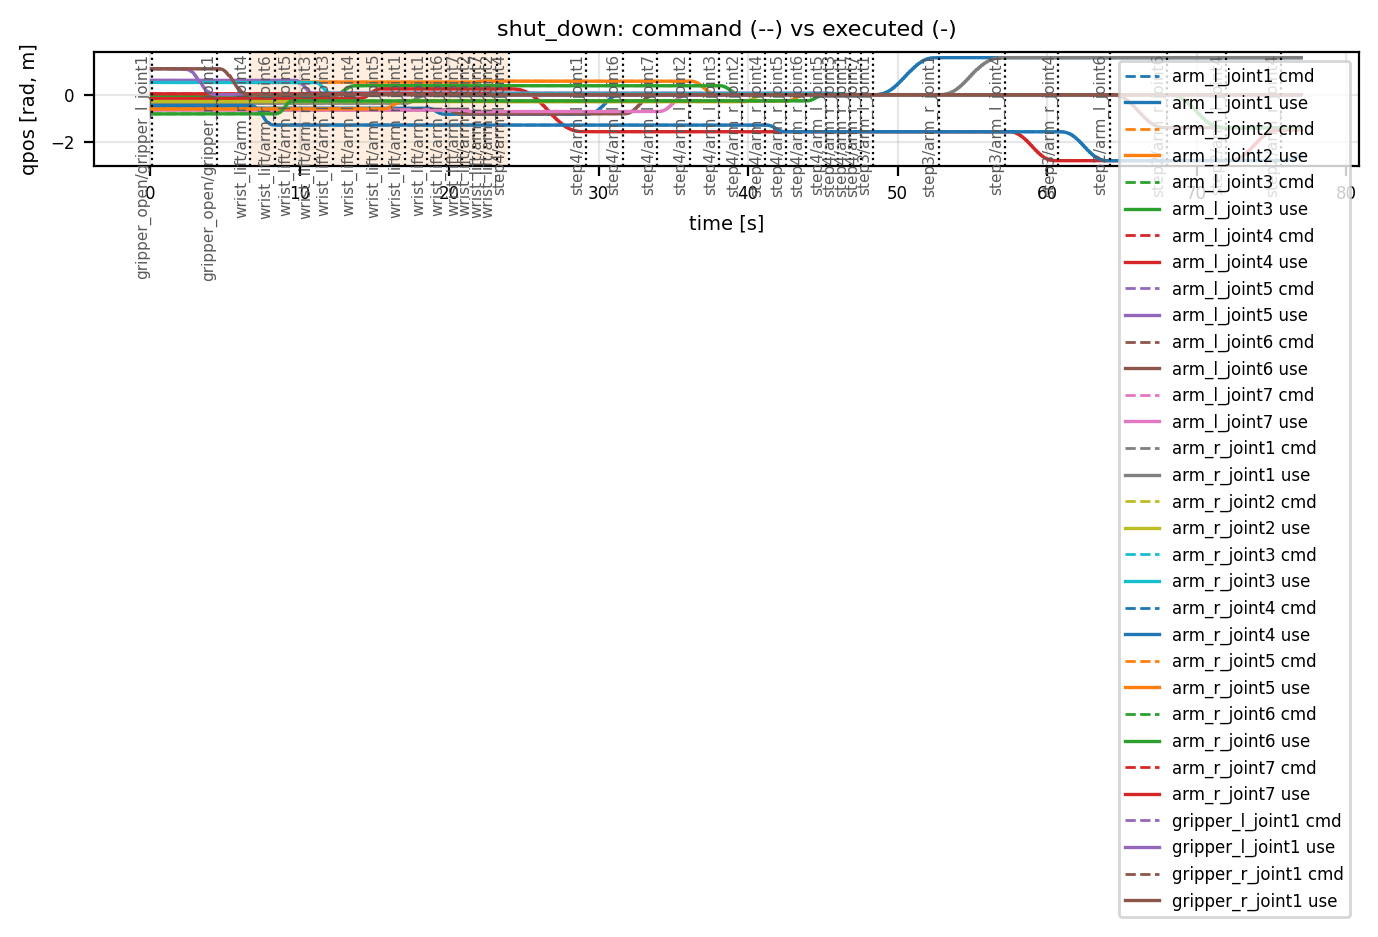

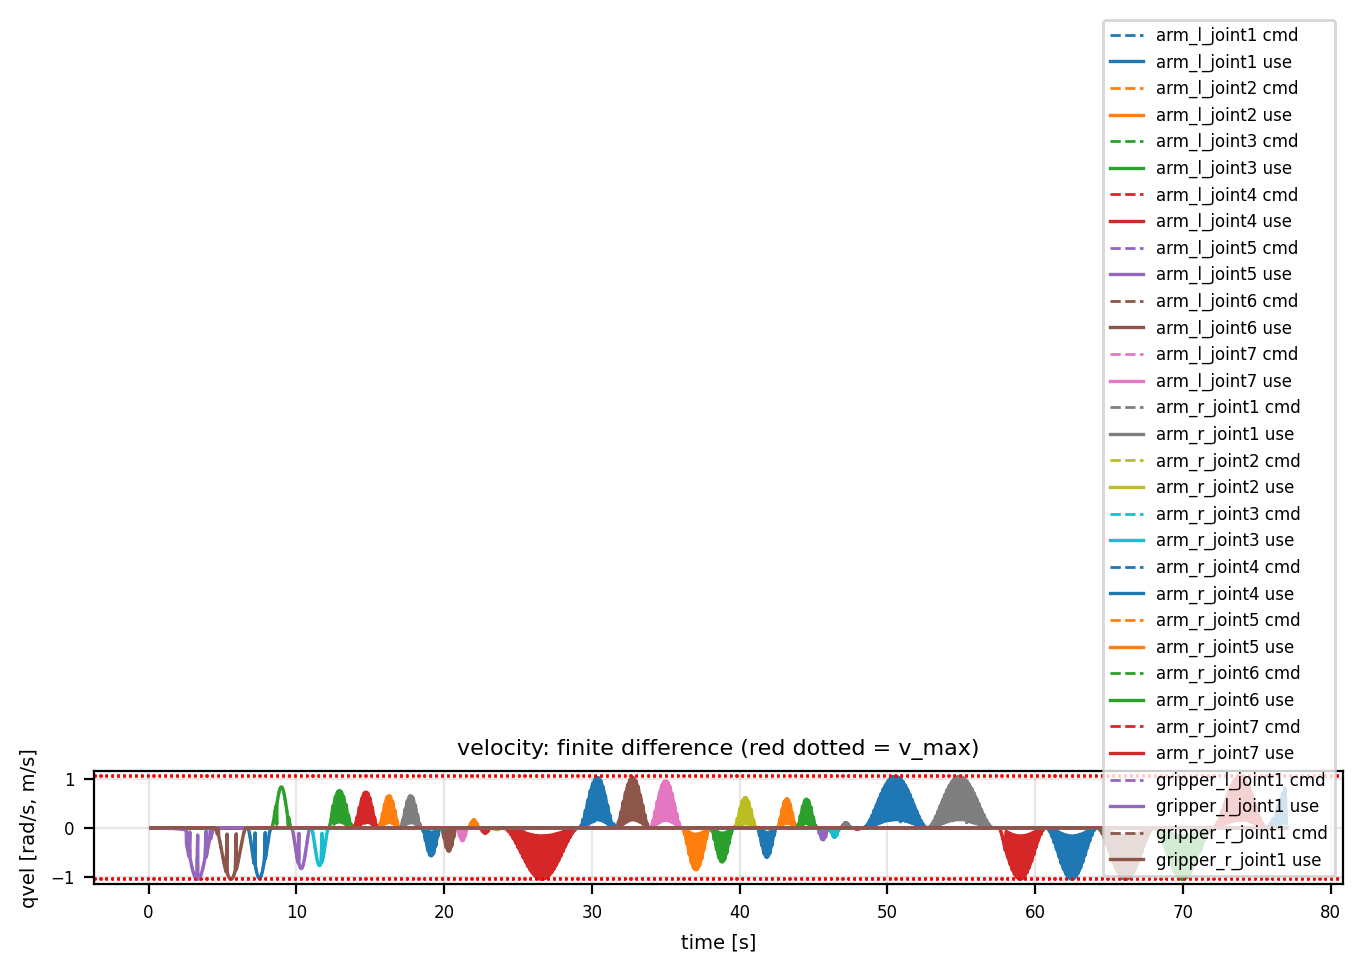

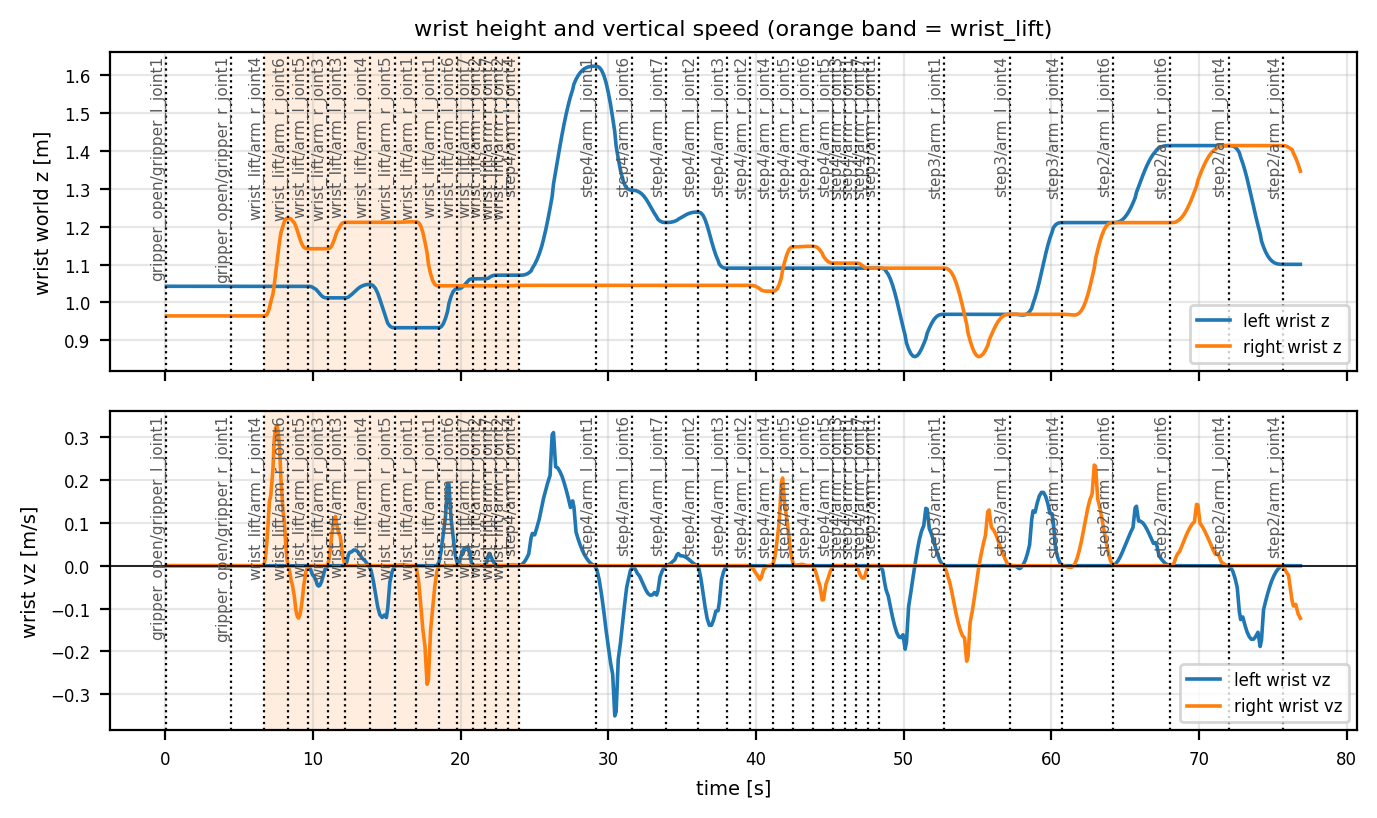

wrist lift          : t=6.68..23.96s (17.28s of a 77.00s motion)
  left  z 1.043 -> 1.072 m (rise +0.029 m), peak |vz| 0.191 m/s
  right z 0.965 -> 1.045 m (rise +0.081 m), peak |vz| 0.328 m/s

                   segment   hand  chord [m]  bulge [mm]  bulge/chord
---------------------------------------------------------------------
   wrist_lift/arm_r_joint4  right      0.299        31.2        10.4%
   wrist_lift/arm_r_joint6  right      0.091         6.2         6.8%
   wrist_lift/arm_l_joint5   left      0.055         3.7         6.8%
   wrist_lift/arm_r_joint3  right      0.202        11.6         5.7%
   wrist_lift/arm_l_joint3   left      0.073         4.2         5.7%
   wrist_lift/arm_l_joint4   left      0.156         8.0         5.2%
   wrist_lift/arm_r_joint5  right      0.015         0.6         4.0%
   wrist_lift/arm_r_joint1  right      0.197         8.1         4.1%
   wrist_lift/arm_l_joint1   left      0.153         4.8         3.2%
   wrist_lift/arm_l_joint6   left   

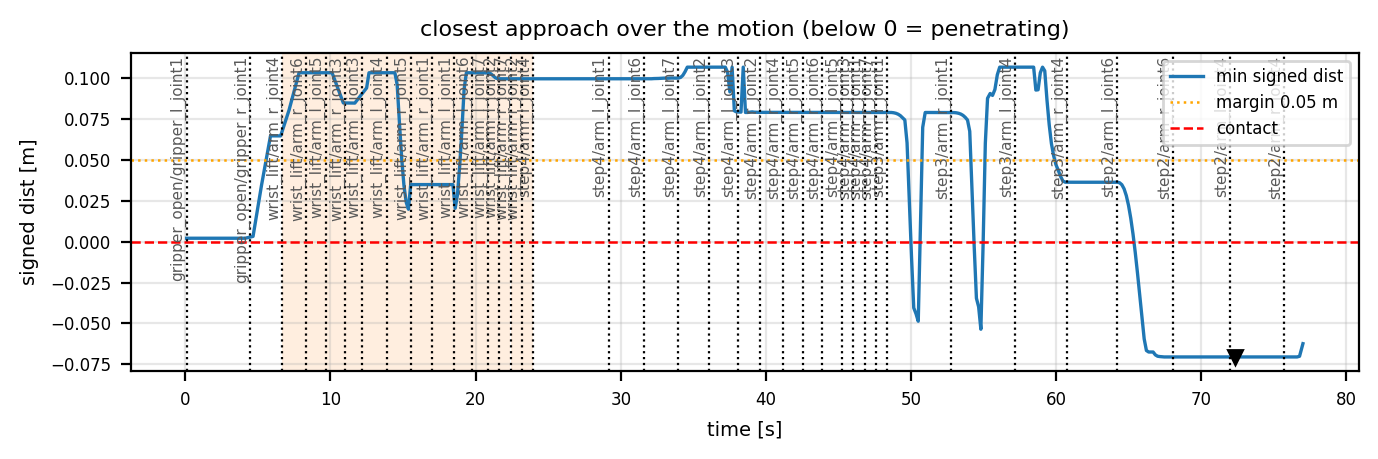


verdict: the motion PENETRATED something -- see the closest-approach row above. Nothing stopped it: the collision check is report-only.


In [8]:
# Analysis -- per-joint position/velocity plots, and the two clipping stages kept apart

if len(exec_log["t"]) < 3:
    raise RuntimeError("No motion logged. Run the loop cell and trigger a Motion command first.")

log_t     = np.array(exec_log["t"], dtype=np.float64)
log_q_cmd = np.array(exec_log["q_cmd"], dtype=np.float64)
log_q_use = np.array(exec_log["q_use"], dtype=np.float64)
log_dt    = np.array(exec_log["dt"], dtype=np.float64)

# Finite-difference velocity, using each tick's own dt rather than a nominal 1/hz.
dt_step = np.maximum(np.diff(log_t), 1e-9)[:, None]
qv_use  = np.diff(log_q_use, axis=0) / dt_step
qv_cmd  = np.diff(log_q_cmd, axis=0) / dt_step

# Plot only the joints that actually moved; all 19 at once is unreadable.
moved_idxs = np.where(np.max(np.abs(log_q_use - log_q_use[0]), axis=0) > 1e-6)[0]
if len(moved_idxs) == 0:
    moved_idxs = np.arange(min(2, log_q_use.shape[1]))

pri_joint_name_set = set(env.pri_joint_names)

# Segment spans (label, t_start, t_end). Marking only where a change happened
# leaves an 8-leg shut_down as 7 anonymous vertical lines, with no way to tell
# which one is the aggressive leg; the spans are what let each be named on the
# axis and shaded.
seg_labels    = list(exec_log["segment"])
segment_spans = []
span_start    = 0
for i in range(1, len(seg_labels) + 1):
    if i == len(seg_labels) or seg_labels[i] != seg_labels[span_start]:
        segment_spans.append((seg_labels[span_start], float(log_t[span_start]), float(log_t[i - 1])))
        span_start = i

# The Cartesian pre-step of shut_down, highlighted everywhere: it is the one
# segment whose goal was not a stored waypoint but an IK solve made at command
# time, and therefore the one that can surprise.
HIGHLIGHT_SEGMENT = "wrist_lift"

def draw_segments(ax):
    """Name every segment on the time axis and shade the wrist-lift leg."""
    for name, t0, t1 in segment_spans:
        ax.axvline(t0, color='k', ls=':', lw=0.8)
        if name.split('/')[0] == HIGHLIGHT_SEGMENT:
            ax.axvspan(t0, t1, color='tab:orange', alpha=0.13, lw=0, zorder=0)
        ax.text(t0, 0.99, name, transform=ax.get_xaxis_transform(), rotation=90,
                va='top', ha='right', fontsize=5.5, color='0.35')

# ---------------------------------------------------------------------------
# 1) Position
# ---------------------------------------------------------------------------
plt.figure(figsize=(7, 3))
for idx in moved_idxs:
    line, = plt.plot(log_t, log_q_cmd[:, idx], '--', lw=1.0,
                     label=f"{command_joint_names[idx]} cmd")
    plt.plot(log_t, log_q_use[:, idx], '-', lw=1.2, color=line.get_color(),
             label=f"{command_joint_names[idx]} use")
draw_segments(plt.gca())
plt.xlabel("time [s]", fontsize=7); plt.ylabel("qpos [rad, m]", fontsize=7)
plt.title(f"{exec_log_label}: command (--) vs executed (-)", fontsize=8)
plt.legend(fontsize=6); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

# ---------------------------------------------------------------------------
# 2) Velocity, with the limit drawn in
# ---------------------------------------------------------------------------
plt.figure(figsize=(7, 3))
for idx in moved_idxs:
    line, = plt.plot(log_t[1:], qv_cmd[:, idx], '--', lw=1.0,
                     label=f"{command_joint_names[idx]} cmd")
    plt.plot(log_t[1:], qv_use[:, idx], '-', lw=1.2, color=line.get_color(),
             label=f"{command_joint_names[idx]} use")
    plt.axhline( joint_speed_limits[idx], color='r', ls=':', lw=0.8)
    plt.axhline(-joint_speed_limits[idx], color='r', ls=':', lw=0.8)
plt.xlabel("time [s]", fontsize=7); plt.ylabel("qvel [rad/s, m/s]", fontsize=7)
plt.title("velocity: finite difference (red dotted = v_max)", fontsize=8)
plt.legend(fontsize=6); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

# ---------------------------------------------------------------------------
# 3) Where the wrists actually went -- the Cartesian path behind the joint plots
# ---------------------------------------------------------------------------
# `wrist_lift` is the only segment specified in Cartesian space ("raise world z
# to the height `step4` has") but executed in joint space, so the qpos plots
# above cannot answer the question that step exists to answer: how far, and how
# fast, did the wrist actually go up? Replay the logged q_use through FK to find
# out -- `env.forward` is kinematics only, so this costs nothing, and the pose
# the cell started from is put back afterwards.
n_fk_max  = 600                                  # FK on every tick of a 30s log is wasteful
fk_stride = max(1, int(np.ceil(len(log_t) / n_fk_max)))
fk_idxs   = np.arange(0, len(log_t), fk_stride)
fk_t      = log_t[fk_idxs]

q_before = env.get_qpos(joint_names=command_joint_names).copy()
try:
    wrist_p = {hand_type: np.zeros((len(fk_idxs), 3)) for hand_type in SG2_HAND_TYPES}
    for row, idx in enumerate(fk_idxs):
        env.forward(q=log_q_use[idx], joint_names=command_joint_names)
        for hand_type in SG2_HAND_TYPES:
            wrist_p[hand_type][row] = t2p(get_sg2_wrist_control_T(env, hand_type))
finally:
    env.forward(q=q_before, joint_names=command_joint_names)

fig, axes = plt.subplots(2, 1, figsize=(7, 4.2), sharex=True)
for hand_type in SG2_HAND_TYPES:
    z  = wrist_p[hand_type][:, 2]
    vz = np.gradient(z, fk_t)                    # vertical speed of the wrist itself
    axes[0].plot(fk_t, z,  '-', lw=1.3, label=f"{hand_type} wrist z")
    axes[1].plot(fk_t, vz, '-', lw=1.3, label=f"{hand_type} wrist vz")
for ax in axes:
    draw_segments(ax)
    ax.grid(alpha=0.3); ax.legend(fontsize=6)
axes[1].axhline(0.0, color='k', lw=0.6)
axes[0].set_ylabel("wrist world z [m]", fontsize=7)
axes[1].set_ylabel("wrist vz [m/s]", fontsize=7)
axes[1].set_xlabel("time [s]", fontsize=7)
axes[0].set_title("wrist height and vertical speed (orange band = wrist_lift)", fontsize=8)
plt.tight_layout(); plt.show()

lift_spans = [span for span in segment_spans if span[0].split("/")[0] == HIGHLIGHT_SEGMENT]
if len(lift_spans) == 0:
    print("wrist lift          : no wrist_lift segment in this motion -- either it was not a "
          "shut_down, or both wrists were already at or above the lift height.")
else:
    # One wrist_lift shows up as several legs, one per joint: take the span
    # from the first to the last of them.
    lift_t0 = lift_spans[0][1]
    lift_t1 = lift_spans[-1][2]
    in_lift = (fk_t >= lift_t0) & (fk_t <= lift_t1)
    print(f"wrist lift          : t={lift_t0:.2f}..{lift_t1:.2f}s "
          f"({lift_t1 - lift_t0:.2f}s of a {log_t[-1]:.2f}s motion)")
    for hand_type in SG2_HAND_TYPES:
        z = wrist_p[hand_type][in_lift, 2]
        if len(z) < 2:
            continue
        vz = np.gradient(z, fk_t[in_lift])
        # The rise is not a constant "small lift": it is (step4 wrist z) - (wrist z
        # at command time), so a hand left down by the table gets tens of cm.
        print(f"  {hand_type:<5s} z {z[0]:.3f} -> {z[-1]:.3f} m (rise {z[-1] - z[0]:+.3f} m), "
              f"peak |vz| {np.max(np.abs(vz)):.3f} m/s")

# How straight was each leg? Both planners end a segment at the same wrist pose,
# so the endpoints carry no information -- the bulge away from the chord between
# them is the whole difference between one route and another.
print()
print(f"{'segment':>26s} {'hand':>6s} {'chord [m]':>10s} {'bulge [mm]':>11s} {'bulge/chord':>12s}")
print("-" * (26 + 43))
for name, t0, t1 in segment_spans:
    m = (fk_t >= t0) & (fk_t <= t1)
    if int(np.sum(m)) < 3:
        continue
    for hand_type in SG2_HAND_TYPES:
        bulge, chord = path_straightness(wrist_p[hand_type][m])
        if chord < 1e-4:
            continue
        print(f"{name:>26s} {hand_type:>6s} {chord:10.3f} {1e3 * bulge:11.1f} "
              f"{100.0 * bulge / chord:11.1f}%")

# ---------------------------------------------------------------------------
# 4) Per-segment breakdown -- which leg of the motion is the aggressive one
# ---------------------------------------------------------------------------
# `estimate_duration` returns the SHORTEST T that still respects v_max and a_max,
# so every segment is planned to run at its ceiling. "Aggressive" is therefore
# never a limit violation here (v/v_max stays ~1.0 throughout); it is a segment
# whose joint-space displacement is much larger than its Cartesian displacement
# looks. One row per LEG here, so the pace-setting joint is simply the joint the
# leg was driving -- the value of the column is the travel next to it.
# Both ratios are finite differences of the executed qpos and carry the same
# noise as the plots above -- read them as "about 1.0 or not", not to 3 digits.
qa_use = np.diff(qv_use, axis=0) / dt_step[1:]

print()
print(f"{'segment':>26s} {'T [s]':>6s} {'ticks':>6s} {'v/v_max':>8s} {'a/a_max':>8s} "
      f"{'pace-setting joint':>22s} {'its travel':>12s}")
print("-" * 96)
for name, t0, t1 in segment_spans:
    m = (log_t >= t0) & (log_t <= t1)
    if int(np.sum(m)) < 3:
        print(f"{name:>26s} {t1 - t0:6.2f} {int(np.sum(m)):6d} {'-':>8s} {'-':>8s}")
        continue
    v_ratio = np.abs(qv_use[m[1:]]) / joint_speed_limits
    a_ratio = np.abs(qa_use[m[2:]]) / joint_acc_limits
    j       = int(np.argmax(np.max(v_ratio, axis=0)))
    travel  = float(np.max(np.abs(log_q_use[m][:, j] - log_q_use[m][0, j])))
    travel_text = (f"{1e3 * travel:7.1f} mm" if command_joint_names[j] in pri_joint_name_set
                   else f"{np.rad2deg(travel):7.1f} deg")
    print(f"{name:>26s} {t1 - t0:6.2f} {int(np.sum(m)):6d} "
          f"{np.max(v_ratio):8.2f} {np.max(a_ratio):8.2f} "
          f"{command_joint_names[j]:>22s} {travel_text:>12s}")

# ---------------------------------------------------------------------------
# 5) The two clipping stages, reported separately
# ---------------------------------------------------------------------------
n_tick    = len(log_t)
n_limited = int(np.sum(exec_log["limited"]))
n_clipped = int(np.sum(exec_log["clipped"]))
gap       = np.abs(log_q_cmd - log_q_use)

coarse_segments = dict.fromkeys(s.split('/')[0] for s in exec_log['segment'])
print(f"motion              : {exec_log_label}  ({' -> '.join(coarse_segments)})")
print(f"ticks               : {n_tick} over {log_t[-1]:.2f} s")
print(f"loop timing         : dt median {1e3 * np.median(log_dt):.1f} ms "
      f"(nominal {1e3 / play_hz:.1f} ms) -> effective {1.0 / np.median(log_dt):.1f} Hz")
print(f"rate limit engaged  : {n_limited} / {n_tick} ticks ({100.0 * n_limited / n_tick:.1f}%), "
      f"max dq/dq_max {np.max(exec_log['dq_ratio']):.3f}x")
print(f"joint limit clipped : {n_clipped} / {n_tick} ticks ({100.0 * n_clipped / n_tick:.1f}%)")
print()
print(f"{'joint':<20s} {'max |cmd-use|':>14s} {'deg / mm':>14s}")
for idx in np.argsort(-np.max(gap, axis=0))[:5]:
    value = float(np.max(gap[:, idx]))
    unit  = f"{1e3 * value:10.4f} mm" if command_joint_names[idx] in pri_joint_name_set \
            else f"{np.rad2deg(value):10.4f} deg"
    print(f"{command_joint_names[idx]:<20s} {value:14.3e} {unit:>14s}")

# ---------------------------------------------------------------------------
# 6) How close the motion came to a collision (self + table)
# ---------------------------------------------------------------------------
# Sampled at render_hz while the executor was active, so the resolution is
# coarser than the position plots above -- it answers "how close did it come",
# not "at exactly which millisecond".
if len(coll_log["t"]) == 0:
    print("collision           : not logged -- the Collision row was off during this motion.")
else:
    coll_t    = np.array(coll_log["t"], dtype=np.float64)
    coll_dist = np.array(coll_log["min_dist"], dtype=np.float64)
    finite    = np.isfinite(coll_dist)
    n_warn    = int(np.sum(np.array(coll_log["level"]) == "warning"))
    n_hit     = int(np.sum(np.array(coll_log["level"]) == "collision"))

    if not np.any(finite):
        print(f"collision           : {len(coll_t)} samples, no candidate pair ever in range")
    else:
        worst = int(np.nanargmin(np.where(finite, coll_dist, np.inf)))
        print(f"collision samples   : {len(coll_t)} at ~{render_hz} Hz "
              f"({n_warn} within margin, {n_hit} penetrating)")
        print(f"closest approach    : {coll_dist[worst]:+.4f} m at t={coll_t[worst]:.2f}s "
              f"during [{coll_log['segment'][worst]}]")
        print(f"                      {coll_log['pair'][worst]}")

        plt.figure(figsize=(7, 2.4))
        plt.plot(coll_t, coll_dist, '-', lw=1.2, color='tab:blue', label="min signed dist")
        plt.axhline(collision_margin, color='orange', ls=':', lw=0.9, label=f"margin {collision_margin:.2f} m")
        plt.axhline(0.0, color='r', ls='--', lw=0.9, label="contact")
        plt.plot(coll_t[worst], coll_dist[worst], 'v', color='k', ms=5)
        draw_segments(plt.gca())
        plt.xlabel("time [s]", fontsize=7); plt.ylabel("signed dist [m]", fontsize=7)
        plt.title("closest approach over the motion (below 0 = penetrating)", fontsize=8)
        plt.legend(fontsize=6); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

print()
if len(coll_log["t"]) > 0 and int(np.sum(np.array(coll_log["level"]) == "collision")) > 0:
    print("verdict: the motion PENETRATED something -- see the closest-approach row above. "
          "Nothing stopped it: the collision check is report-only.")
elif n_clipped > 0:
    print("verdict: the GOAL was out of range -- np.clip truncated it. "
          "Fix the waypoint; the offline check cell names the joint.")
elif n_limited > 0:
    print("verdict: the RATE LIMIT engaged -- the loop fell behind and dt hit the executor's "
          f"ceiling ({1e3 * executor.dt_max:.0f} ms). Lower render_hz.")
else:
    print("verdict: OK -- the planned trajectory respected both limits on its own.")
    # "Within the limits" and "gentle" are different claims, and only the first is
    # checked above. Say so, rather than letting an OK verdict imply the second.
    if len(lift_spans) > 0:
        print("         Note the wrist_lift row in the per-segment table: it runs at v_max like "
              "every other segment, so if it looked violent the cause is its travel, not a "
              "planner fault. Shorten it by capping the lift height, or slow it by raising "
              "min_duration for that segment.")